In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [3]:
# Conver MNIST Image Files into a Tensor of 4-Dimensions (# of images, Height, Width, Color Channels)
transform = transforms.ToTensor()

In [5]:
# Training data
train_data = datasets.MNIST(root='./cnn_data', train=True, download=True, transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 13.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 360kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.42MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.5MB/s]


In [6]:
# Test Data
test_data = datasets.MNIST(root='./cnn_data', train=False, download=True, transform=transform)

In [7]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./cnn_data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [9]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./cnn_data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [11]:
# Creatae a small batch size for images.. lets say 10
train_loader = DataLoader(train_data, batch_size=10, shuffle=True)
test_loader = DataLoader(test_data, batch_size=10, shuffle=True)

In [12]:
# Define our CNN Model
# Describe convolutional layer and what it is doing ( 2 convolutional layers)
# This is just an example in the next video we will build out the actual model
conv1 = nn.Conv2d(1, 6, 3, 1)
conv2 = nn.Conv2d(6, 16, 3, 1)

In [13]:
# Grab 1 MNIST record (i.e) image data
for i, (X_Train, y_train) in enumerate(train_data):
    break

In [14]:
X_Train

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [30]:
X_Train.shape

torch.Size([1, 28, 28])

In [31]:
x = X_Train.view(1,1,28,28)

In [32]:
# Perform the first convolution
x = F.relu(conv1(x)) # Rectified Linear Unit for activation function

In [33]:
# 1 single image, 6 is the filters we asked for , 26*26
x.shape

torch.Size([1, 6, 26, 26])

In [34]:
# pass thorough the pooling layer
x = F.max_pool2d(x,2,2)

In [35]:
x.shape # 26 / 2 = 13

torch.Size([1, 6, 13, 13])

In [36]:
# Do the second convolution layer
x = F.relu(conv2(x))

In [ ]:
x.shape # Again, we did not set padding, so we lose 2 pixels around outside of the image

torch.Size([1, 16, 11, 11])

In [38]:
# another pooling layer (2nd one)
x = F.max_pool2d(x, 2, 2)

In [ ]:
x.shape # 11/2 = 5.5 but we have to round down, because you can't invent data to round up

torch.Size([1, 16, 5, 5])

In [44]:
# Model class
class ConvolutionalNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1,6,3,1)
        self.conv2 = nn.Conv2d(6,16,3,1)
        # Fully connected Layer
        self.fc1 = nn.Linear(5*5*16,120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, X):
        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2, 2) # 2*2 kernel and stride 2
        # Second pass
        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2) # 2*2 kernel and stride 2

        # Re-view to flatten it out
        X = X.view(-1, 16*5*5) # negative one so that we can vary the batch size

        # Fully connected Layers
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)
        return F.log_softmax(X, dim=1)




In [45]:
# Create an instance of our Model
torch.manual_seed(41)
model = ConvolutionalNetwork()
print(model)

ConvolutionalNetwork(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [46]:
# Loss Function Optimizer
criterian = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # smaller learning rate, longer it takes to train

In [56]:
import time
start_time = time.time()

# Create variables to track things
epochs = 5
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# For loop of epochs
for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    # Train
    for b, (X_Train, y_train) in enumerate(train_loader):
        b+=1 # start our batches at 1
        y_pred = model(X_Train) # get predicted values from the training set. Not falttened 2D
        loss = criterian(y_pred, y_train) # how off are we? Compare the prediction to correct answers in y_train

        predicted = torch.max(y_pred.data, 1)[1] # add up the number of correct predictions. Indexed off the first point
        batch_corr = (predicted == y_train).sum() # how many we got correct from this batch.True = 1, False = 0, sum those up
        trn_corr += batch_corr # keep track as we go along in training

        # update out parameters
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # printout some results
        if b%600 == 0:
            print(f'Epoch: {i} Batch: {b} Loss: {loss.item()}')

    train_losses.append(loss)
    train_correct.append(trn_corr)

    # Test
    with torch.no_grad(): # No gradient so we dont update the weight and biases with the test data
        for b, (X_Test, y_test) in enumerate(test_loader):
            y_val = model(X_Test)
            predicted = torch.max(y_val.data, 1)[1] # Adding up correct predictions
            tst_corr += (predicted == y_test).sum() # T=1 F=0 and sum away

    loss = criterian(y_val, y_test)
    test_losses.append(loss)
    test_correct.append(tst_corr)


current_time = time.time()
total = current_time - start_time
print(f'Training took: {total/60} minutes!')

Epoch: 0 Batch: 600 Loss: 8.354060264537111e-05
Epoch: 0 Batch: 1200 Loss: 0.0007280980935320258
Epoch: 0 Batch: 1800 Loss: 8.654234079585876e-06
Epoch: 0 Batch: 2400 Loss: 1.1813045603048522e-05
Epoch: 0 Batch: 3000 Loss: 0.003695088205859065
Epoch: 0 Batch: 3600 Loss: 0.008690943010151386
Epoch: 0 Batch: 4200 Loss: 7.510177510994254e-07
Epoch: 0 Batch: 4800 Loss: 5.960463411724959e-08
Epoch: 0 Batch: 5400 Loss: 2.753357148321811e-05
Epoch: 0 Batch: 6000 Loss: 0.0001986091083381325
Epoch: 1 Batch: 600 Loss: 3.1589966056344565e-06
Epoch: 1 Batch: 1200 Loss: 2.3603283807460684e-06
Epoch: 1 Batch: 1800 Loss: 2.9802305334669654e-07
Epoch: 1 Batch: 2400 Loss: 0.02986200712621212
Epoch: 1 Batch: 3000 Loss: 1.549720280991096e-07
Epoch: 1 Batch: 3600 Loss: 1.8954160623252392e-06
Epoch: 1 Batch: 4200 Loss: 1.3791563105769455e-05
Epoch: 1 Batch: 4800 Loss: 1.5497141703235684e-06
Epoch: 1 Batch: 5400 Loss: 0.03684081509709358
Epoch: 1 Batch: 6000 Loss: 1.5497198546654545e-07
Epoch: 2 Batch: 600 

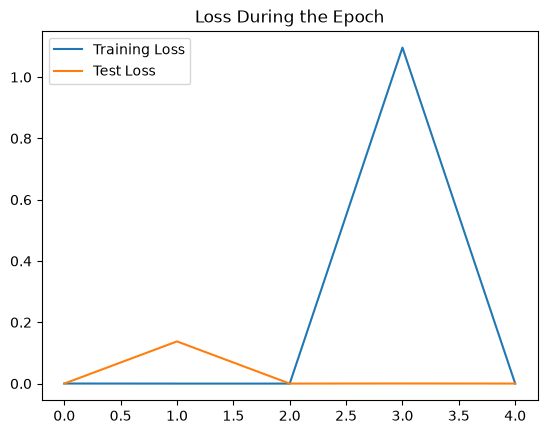

In [57]:
# Graph the loss during epoch
train_losses_for_plotting = [tl.item() for tl in train_losses]
plt.plot(train_losses_for_plotting, label="Training Loss")
plt.plot(test_losses, label="Test Loss")
plt.title("Loss During the Epoch")
plt.legend()

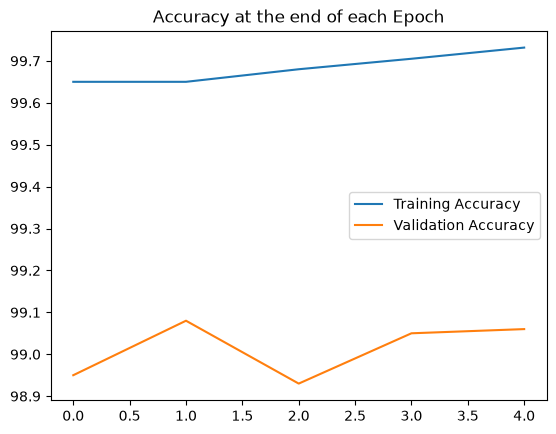

In [58]:
# Graph the accuracy at the end of the epoch
plt.plot([t/600 for t in train_correct], label="Training Accuracy")
plt.plot([t/100 for t in test_correct], label="Validation Accuracy")
plt.title("Accuracy at the end of each Epoch")
plt.legend()

In [59]:
test_load_everything = DataLoader(test_data, batch_size=10000, shuffle=False)

In [60]:
with torch.no_grad():
    correct = 0
    for X_Test, y_test in test_load_everything:
        y_val = model(X_Test)
        predicted = torch.max(y_val, 1)[1]
        correct += (predicted == y_test).sum()

In [61]:
# Did for correct
correct.item()/len(test_data)*100

99.06

In [62]:
# Grab an image
test_data[1978] # Tensor with an image in it...at end, it shows the label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 

In [63]:

# Grab just the data
test_data[1978][0]

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [64]:

# Reshape it
test_data[1978][0].reshape(28,28)


tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000

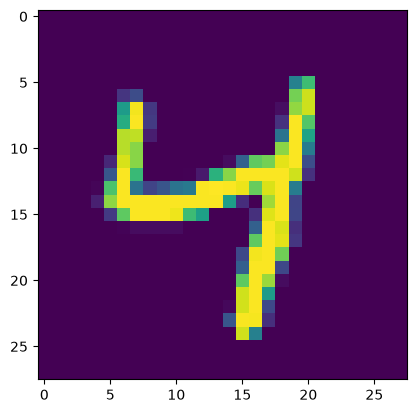

In [65]:
# Show the image
plt.imshow(test_data[1978][0].reshape(28,28))

In [66]:
# pass the image through the model
model.eval()
with torch.no_grad():
    new_prediction = model(test_data[1978][0].view(1,1,28,28)) # batch size of 1, 1 color channel, 28x28 image

In [67]:
# check the prediction and get the probabilities
new_prediction

tensor([[-50.9123, -39.5704, -49.8190, -64.4845,   0.0000, -38.6816, -34.9530,
         -43.0038, -40.0291, -33.9245]])

In [ ]:
new_prediction.argmax() # it shows 4 beacuse the highest probability is 64.4845 and that is referencing number 4 (that is in the image)

tensor(4)